# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [11]:
ROLL_NO = 1024160105         # <-- your full roll number
NAME = "Hazel Latka"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [12]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [13]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [14]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160105   Name: Hazel Latka   Fingerprint: 7547EE2A   Tickets: 12

Ticket_ID                                                                                Ticket_Text
      T01                                   The server is running slowly. Is there another solution?
      T02                       Email stopped responding since yesterday. Is there another solution?
      T03                        Email failed to open during the lab. The same problem occurs again.
      T04                                         The MATLAB has stopped syncing. Please resolve it.
      T05                                        The printer is showing an error. Please resolve it.
      T06                                                     Only 2 of 30 PCs boot after 3.5 hours.
      T07                                               Call me on +91 98765 43210 or 0175-239-3201.
      T08                                                I can't login and I didn't change anything.
      T0

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [15]:
rows = []

for _, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])
    rows.append([
        row["Ticket_ID"],
        len(p["sentences"]),
        len(p["tokens"]),
        len(p["punct"]),
        len(p["stops"]),
        len(set(p["tokens"])),
        len(p["final"])
    ])

result = pd.DataFrame(rows, columns=[
    "Ticket_ID",
    "Sentences",
    "Tokens",
    "Punctuation",
    "Stopwords",
    "Unique_Tokens",
    "Final_Tokens"
])

result.loc[len(result)] = [
    "TOTAL",
    result["Sentences"].sum(),
    result["Tokens"].sum(),
    result["Punctuation"].sum(),
    result["Stopwords"].sum(),
    result["Unique_Tokens"].sum(),
    result["Final_Tokens"].sum()
]

display(result)

p = process_ticket(df.iloc[0]["Ticket_Text"])

print("Tokens:", p["tokens"])
print("Punctuation tokens:", p["punct"])
print("Stopwords:", p["stops"])
print("Final tokens:", p["final"])

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,11,2,4,10,5
1,T02,2,11,2,2,11,7
2,T03,2,14,2,6,12,6
3,T04,2,10,2,3,9,5
4,T05,2,11,2,4,10,5
5,T06,1,10,1,3,10,6
6,T07,1,9,1,3,9,5
7,T08,1,11,1,4,9,6
8,T09,1,9,2,1,9,6
9,T10,2,13,2,5,12,6


Tokens: ['the', 'server', 'is', 'running', 'slowly', '.', 'is', 'there', 'another', 'solution', '?']
Punctuation tokens: ['.', '?']
Stopwords: ['the', 'is', 'is', 'there']
Final tokens: ['server', 'running', 'slowly', 'another', 'solution']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*Some final tokens such as n't, 's, and ca are not complete real words. They are produced by word_tokenize() when contractions are split into separate tokens. For example, can't may be tokenized as ca and n't, while possessive or contracted forms may produce 's.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [16]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
import re

for _, row in df.iterrows():
    text = row["Ticket_Text"]

    long_words = re.findall(r"\b[A-Za-z]{6,}\b", text)
    numbers = re.findall(r"\b\d+(?:\.\d+)+\b|\b\d+\b", text)
    capitalized_words = re.findall(r"\b[A-Z][A-Za-z]*\b", text)
    vowel_words = re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)

    replaced = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    replaced = re.sub(r"https?://[^\s]+|www\.[^\s]+", "<URL>", replaced)
    replaced = re.sub(r"\+?\d[\d\s()-]{7,}\d", "<PHONE>", replaced)

    print(row["Ticket_ID"])
    print("Words > 5 letters:", long_words)
    print("Numbers:", numbers)
    print("Capitalized words:", capitalized_words)
    print("Vowel words:", vowel_words)
    print("Replaced:", replaced)
    print()

for text in TEST_LINES:
    print("Text:", text)
    print("Words > 5 letters:", re.findall(r"\b[A-Za-z]{6,}\b", text))
    print("Numbers:", re.findall(r"\b\d+(?:\.\d+)+\b|\b\d+\b", text))
    print("Capitalized words:", re.findall(r"\b[A-Z][A-Za-z]*\b", text))
    print("Vowel words:", re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text))

    replaced = re.sub(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", "<EMAIL>", text)
    replaced = re.sub(r"https?://[^\s]+|www\.[^\s]+", "<URL>", replaced)
    replaced = re.sub(r"\+?\d[\d\s()-]{7,}\d", "<PHONE>", replaced)

    print("Replaced:", replaced)
    print()
# Your code

T01
Words > 5 letters: ['server', 'running', 'slowly', 'another', 'solution']
Numbers: []
Capitalized words: ['The', 'Is']
Vowel words: ['is', 'Is', 'another']
Replaced: The server is running slowly. Is there another solution?

T02
Words > 5 letters: ['stopped', 'responding', 'yesterday', 'another', 'solution']
Numbers: []
Capitalized words: ['Email', 'Is']
Vowel words: ['Email', 'Is', 'another']
Replaced: Email stopped responding since yesterday. Is there another solution?

T03
Words > 5 letters: ['failed', 'during', 'problem', 'occurs']
Numbers: []
Capitalized words: ['Email', 'The']
Vowel words: ['Email', 'open', 'occurs', 'again']
Replaced: Email failed to open during the lab. The same problem occurs again.

T04
Words > 5 letters: ['MATLAB', 'stopped', 'syncing', 'Please', 'resolve']
Numbers: []
Capitalized words: ['The', 'MATLAB', 'Please']
Vowel words: ['it']
Replaced: The MATLAB has stopped syncing. Please resolve it.

T05
Words > 5 letters: ['printer', 'showing', 'Please', 'res

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*Most of the capitalized words are capitalized only because they occur at the beginning of a sentence. Words such as “The”, “Email”, “Wifi”, “Call” and “Mail” are examples.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [17]:
# Your code
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = r"""https?://[^\s]+|www\.[^\s]+|[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|\+?\d[\d\s()-]{7,}\d|\d+(?:\.\d+)+|[A-Za-z]+(?:[-'][A-Za-z]+)*|[^\w\s]"""

tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for text in TEST_LINES:
    print("Text:", text)
    print("My tokenizer:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))
    print()

for _, row in df.iterrows():
    text = row["Ticket_Text"]
    print(row["Ticket_ID"], my_tokenize(text))

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
My tokenizer: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
My tokenizer: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', ',', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
My tokenizer: ['T

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*My tokenizer preserves contractions such as isn't as one token, while word_tokenize() may split them into is and n't. It preserves hyphenated words such as Wi-Fi and state-of-the-art as single tokens, whereas word_tokenize() may split them. It also keeps special patterns such as version numbers, email addresses, URLs and phone numbers together as single meaningful tokens instead of breaking them into smaller parts.     UCS420_Assignment7

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [18]:
# Your code
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download("wordnet", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer(r"(ing|ed|s)$", min=4)
lemmatizer = WordNetLemmatizer()

final_tokens = []

for _, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])
    final_tokens.extend(p["final"])

unique_tokens = sorted(set(final_tokens))

def get_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged = nltk.pos_tag(unique_tokens)

rows = []

for word, tag in tagged:
    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regexp_word = regexp_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(word, get_pos(tag))

    if len({word, porter_word, lancaster_word, regexp_word, lemma_word}) > 1:
        rows.append([
            word,
            porter_word,
            lancaster_word,
            regexp_word,
            lemma_word
        ])

stem_df = pd.DataFrame(rows, columns=[
    "Word",
    "Porter",
    "Lancaster",
    "Regexp",
    "Lemma"
])

display(stem_df)

,Word,Porter,Lancaster,Regexp,Lemma
0,another,anoth,anoth,another,another
1,anything,anyth,anyth,anyth,anything
2,call,call,cal,call,call
3,campus,campu,camp,campu,campus
4,change,chang,chang,change,change
5,computer,comput,comput,computer,computer
6,connected,connect,connect,connect,connect
7,crashes,crash,crash,crashe,crash
8,error,error,er,error,error
9,failed,fail,fail,fail,fail


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*I chose the suffixes ing, ed, and s because words in my dataset contain these common endings, such as running, showing, worked, stopped, crashes and works. Removing these suffixes helps reduce related word forms to simpler stems. The different stemmers may produce different results because Porter and Lancaster use different stemming rules, while POS-aware WordNet lemmatization uses the grammatical role of the word to obtain a meaningful base form.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Corpus,Total Tokens,Unique Tokens,TTR
0,S1,140,82,0.585714
1,S2,119,78,0.655462
2,S3,73,56,0.767123
3,S4,73,53,0.726027


Top 10 words S1: [('.', 17), ('the', 7), ('is', 5), ('it', 4), ('another', 3), ('stopped', 3), ('on', 3), ("n't", 3), ('there', 2), ('solution', 2)]
Top 10 words S3: [('another', 3), ('stopped', 3), ("n't", 3), ('solution', 2), ('email', 2), ('yesterday', 2), ('problem', 2), ('occurs', 2), ('syncing', 2), ('please', 2)]


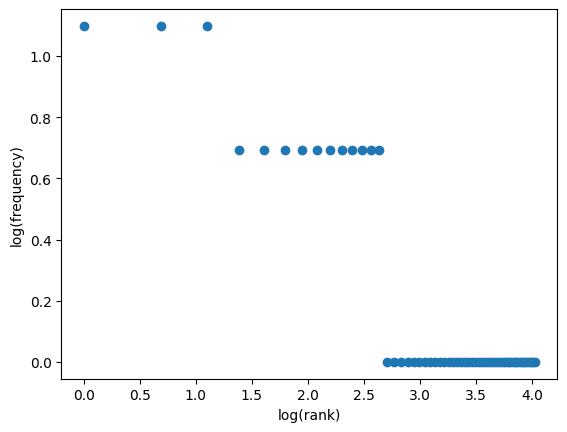

Top 5 bigrams S1: [(('.', 'the'), 4), (('.', 'is'), 2), (('is', 'there'), 2), (('there', 'another'), 2), (('another', 'solution'), 2)]
Top 5 bigrams S3: [(('another', 'solution'), 2), (('solution', 'email'), 2), (('problem', 'occurs'), 2), (('stopped', 'syncing'), 2), (('please', 'resolve'), 2)]


In [19]:
# Your code
from collections import Counter
from nltk.util import bigrams
import matplotlib.pyplot as plt
import math

S1 = []
S2 = []
S3 = []

for _, row in df.iterrows():
    p = process_ticket(row["Ticket_Text"])
    S1.extend(p["tokens"])
    S2.extend([x for x in p["tokens"] if x not in p["punct"]])
    S3.extend(p["final"])

S4 = [porter.stem(x) for x in S3]

rows = []

for name, corpus in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    total = len(corpus)
    unique = len(set(corpus))
    ttr = unique / total if total else 0
    rows.append([name, total, unique, ttr])

stats = pd.DataFrame(rows, columns=[
    "Corpus", "Total Tokens", "Unique Tokens", "TTR"
])

display(stats)

print("Top 10 words S1:", Counter(S1).most_common(10))
print("Top 10 words S3:", Counter(S3).most_common(10))

freq = Counter(S3)
frequencies = sorted(freq.values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.scatter(
    [math.log(r) for r in ranks],
    [math.log(f) for f in frequencies]
)
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.show()

print("Top 5 bigrams S1:", Counter(bigrams(S1)).most_common(5))
print("Top 5 bigrams S3:", Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*TTR changes from S1 to S4 because preprocessing removes punctuation and stopwords, while stemming reduces different forms of words to a common stem. This decreases the number of unique tokens and therefore changes the type-token ratio.

For isn't, word_tokenize() splits it into is and n't, while my custom tokenizer preserves isn't as one token. This happens because my regular expression is designed to preserve contractions.

Stemming can produce undesirable non-words. For example, Lancaster stemming may reduce a valid word to a shortened form that is not an actual English word. This happens because stemming removes word endings using rules without considering the meaning of the word.

POS-aware lemmatization preserves meaning better because it uses the grammatical role of the word to find its valid base form. For example, a verb form can be converted to its meaningful dictionary form, whereas stemming may simply cut off characters and produce a non-word.